Epoch 1/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 1s 26ms/step - accuracy: 0.6114 - loss: 0.6567 - val_accuracy: 0.5510 - val_loss: 0.6672
Epoch 2/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.6684 - loss: 0.6117 - val_accuracy: 0.5918 - val_loss: 0.6453
Epoch 3/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.7150 - loss: 0.5787 - val_accuracy: 0.6327 - val_loss: 0.6245
Epoch 4/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.7565 - loss: 0.5476 - val_accuracy: 0.6735 - val_loss: 0.6050
Epoch 5/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.7617 - loss: 0.5183 - val_accuracy: 0.6531 - val_loss: 0.5865
Epoch 6/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.7772 - loss: 0.4902 - val_accuracy: 0.6531 - val_loss: 0.5700
Epoch 7/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.7979 - loss: 0.4651 - val_accuracy: 0.6939 - val_loss: 0.5563
Epoch 8/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.7979 - loss: 0.4429 - val_accuracy: 0.6939 - val_loss: 0.5461

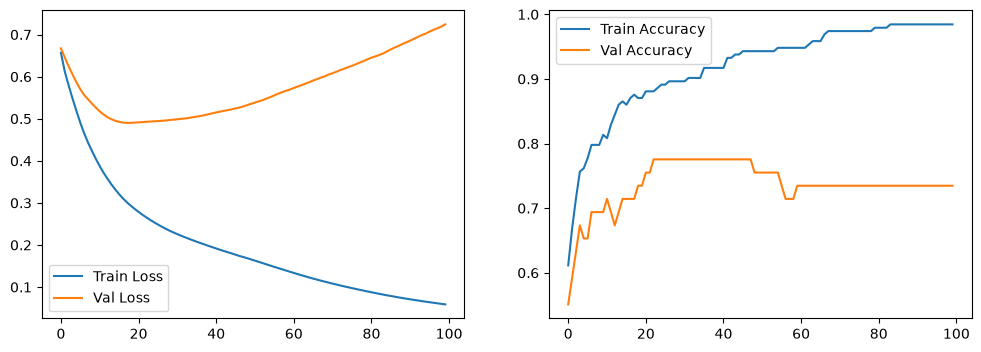

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.8361 - loss: 0.4835
Тестовая точность: 0.8361


In [2]:
# Бинарная классификация медицинских данных

# Импорт библиотек
import pandas as pd
import numpy as np
import tensorflow as tf
from tensorflow import keras
import matplotlib.pyplot as plt

# Установка seed для воспроизводимости
keras.utils.set_random_seed(42)

# Загрузка и предобработка данных
df = pd.read_csv("heart.csv")

# Определение категориальных и числовых признаков
categorical_vars = ['sex', 'cp', 'fbs', 'restecg', 'exang', 'ca', 'thal']
numeric_vars = ['age', 'trestbps', 'chol', 'thalach', 'oldpeak', 'slope']

# One-hot encoding и разделение данных
df_encoded = pd.get_dummies(df, columns=categorical_vars, dtype=int)
train_df = df_encoded.sample(frac=0.8, random_state=42)
test_df = df_encoded.drop(train_df.index)

# Нормализация числовых признаков
mean = train_df[numeric_vars].mean()
std = train_df[numeric_vars].std()
train_df[numeric_vars] = (train_df[numeric_vars] - mean) / std
test_df[numeric_vars] = (test_df[numeric_vars] - mean) / std

# Преобразование в numpy массивы
X_train = train_df.drop('target', axis=1).to_numpy()
y_train = train_df['target'].to_numpy()
X_test = test_df.drop('target', axis=1).to_numpy()
y_test = test_df['target'].to_numpy()

# Создание модели с использованием Input слоя
input_layer = keras.layers.Input(shape=(X_train.shape[1],))
model = keras.Sequential([
    input_layer,
    keras.layers.Dense(32, activation='relu'),
    keras.layers.Dense(16, activation='relu'),
    keras.layers.Dense(1, activation='sigmoid')
])

# Компиляция модели
model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

# Обучение модели
batch_size = 32
epochs = 100
history = model.fit(
    X_train, y_train,
    validation_split=0.2,
    epochs=epochs,
    batch_size=batch_size,
    verbose=1
)

# Визуализация результатов
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Val Loss')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Val Accuracy')
plt.legend()

plt.show()

# Оценка модели
test_loss, test_accuracy = model.evaluate(X_test, y_test)
print(f'Тестовая точность: {test_accuracy:.4f}')

# Сохранение модели (опционально)
# model.save('heart_disease_model.h5')
